# 03a Compare: per-element verdicts for the CRAS room, against the real model

**Slice.** One room of the CRAS lab ("room B", the box recorded in `01_cras_slice.json`): the 1 cm scan cache cut to that box, and the 35 model elements that touch the box. Furniture and proxies are clutter and never get a verdict.

**Question.** Starting from notebook 01's recorded transform, what does each of the 35 elements get (OK, shifted, not confirmed) at the USIBD LOA30 tolerance, and how much does it matter whether the scan classes (oracle labels) are used to separate clutter from elements?

Sections: (1) load, (2) frame: a coarse check of the recorded transform, then ICP refinement and the correction it makes, (3) comparison per element, (4) with vs without oracle labels, (5) outputs, then the answer.
Terms (scan, model, element, clutter, scan class, oracle labels, registration residual, tolerance, verdict) are defined in [CONTEXT.md](../CONTEXT.md).
All randomness is seeded. Nothing is written outside `outputs/03a/` (gitignored).

In [1]:
import csv, json, os, resource, time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import: skips Open3D's Jupyter web-visualizer banner
import open3d as o3d
from IPython.display import Image, display

from scan_vs_bim.load import load_ifc_elements, merge_meshes

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "font.size": 9})
o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
reg = o3d.pipelines.registration

# All parameters in one place. Lengths in metres. Judgement calls are marked (not from a standard).
SEED = 0
CRAS = Path("../data/cras")
CACHE, IFC = CRAS / "cras_voxel_1cm.npz", CRAS / "craslabbim.ifc"
SLICE = Path("01_cras_slice.json")  # written by notebook 01: recorded transform, room box, the 35 elements
OUT = Path("../outputs/03a")  # gitignored; never write outside outputs/
OUT.mkdir(parents=True, exist_ok=True)

# Scan classes (index = class id in the cache) and the ones the model has elements for (the rest is clutter)
CLASS_NAMES = ["unassigned", "ceiling", "floor", "wall", "door", "window", "desk", "chair", "cabinet", "mobile cabinet",
               "shelf", "vents", "water tank", "bin", "box", "board", "computer", "screen", "printer", "vest", "switch",
               "paper dispenser", "alcohol dispenser", "cable", "phone", "robot", "water kettle", "stairs", "ladder",
               "oil heater", "divider", "hanger", "fan", "water dispenser"]
ELEMENT_SCAN_CLASSES = ("ceiling", "floor", "wall", "door", "window", "stairs")
ELEMENT_CLASSES = ("IfcWallStandardCase", "IfcColumn", "IfcDoor", "IfcWindow", "IfcSlab", "IfcCovering", "IfcStairFlight")  # 01's list

# Comparison
TOL = 0.015  # USIBD LOA30: at most 15 mm at 2 sigma (95 %); quoted in section 3
BAND = 0.10  # (judgement call) scan points further than this from every element surface are ignored; the same as 00
PAD = BAND  # (judgement call) the room box is padded by this much when cropping, see section 3 for why
MIN_POINTS = 2000  # (judgement call) 1 cm voxels give one point per cm2, so 2000 points is about 0.2 m2 (a 45 cm square) of scanned surface
MIN_FRAC_OK = 0.8  # (judgement call) share of points within TOL for OK; the same as 00, so the notebooks agree

# Frame: coarse check (FPFH + RANSAC as in 02), then ICP refinement
N_MODEL_SAMPLES, MODEL_CLIP = 3_000_000, 0.3  # points sampled on the 35 elements; kept within this margin of the box
VOXEL = 0.10  # (judgement call) 02 uses 0.8 % of the model diagonal; the room is about 12 m across
NORMAL_RADIUS, FPFH_RADIUS = 2 * VOXEL, 5 * VOXEL
RANSAC_DIST, RANSAC_ITERS, RANSAC_CONFIDENCE = 1.5 * VOXEL, 1_000_000, 0.999
RANSAC_SEEDS = (0, 1, 2, 3, 4)
ICP_DIST = 0.10  # plain point-to-plane ICP; the same as 00
ICP_FINE_DIST, TUKEY_K = 0.05, 0.02  # robust pass: Tukey loss gives residuals beyond 2 cm no weight; the same as 00
# Sanity bounds on the ICP correction, not a standard: 01 fitted the recorded transform on the same surfaces, so a refinement that
# moves the room by more than 5 cm (3x the tolerance) or turns it by more than 0.5 deg (3.5 cm at 4 m) has found something else.
SANITY_ROT_DEG, SANITY_TRANS_M = 0.5, 0.05

T0 = time.time()
def peak_rss_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9  # bytes on macOS


def apply(T, p):
    # Rigid transform T (4x4) applied to points p (n, 3); float32 in, float32 out.
    return (p @ T[:3, :3].T.astype(np.float32) + T[:3, 3].astype(np.float32)).astype(np.float32)

## 1. Load: the 35 room elements, then the scan cut to the room

The inputs are the contract written by notebook 01: `frame.scan_to_model_4x4` (apply it to scan points to get the model frame), `room.box_model_frame` (in the model frame), the 35 element GlobalIds with `inside_box`, and `scanner_positions.recovered`.

Only the 35 elements are tessellated (`load_ifc_elements(..., only_guids=...)`), which takes seconds instead of minutes. The scan cache is transformed in chunks and cropped at once, and the full arrays are deleted, to keep the peak low. The crop is the box **padded by `PAD`** on every side (why: section 3); `in_box` marks the points inside the box itself.

In [2]:
slice_ = json.loads(SLICE.read_text())
ROOM, FRAME = slice_["room"], slice_["frame"]
T_REC = np.array(FRAME["scan_to_model_4x4"])  # scan frame -> model frame, as recorded by 01
BOX = ROOM["box_model_frame"]
box_lo = np.array([BOX[k] for k in ("xmin", "ymin", "zmin")])
box_hi = np.array([BOX[k] for k in ("xmax", "ymax", "zmax")])
GUIDS = ROOM["element_global_ids"]
META = {e["global_id"]: e for e in ROOM["elements"]}
print(f"01: frame answer {FRAME['answer']!r} (as delivered), recorded transform yaw {FRAME['yaw_deg']:.2f} deg, tilt {FRAME['tilt_deg']:.2f} deg, "
      f"translation {np.round(FRAME['translation_m'], 3)} m")
print(f"01: scanner positions recovered: {slice_['scanner_positions']['recovered']} "
      f"({slice_['scanner_positions']['n_found']} of {slice_['scanner_positions']['n_expected']}, none inside the room box)")

t = time.time()
by_id = {e.global_id: e for e in load_ifc_elements(IFC, only_guids=GUIDS)}  # tessellation first: it has the higher memory peak
assert set(by_id) == set(GUIDS) and len(GUIDS) == 35, "not all 35 room elements were found in the IFC"
elements = [by_id[g] for g in GUIDS]
assert all(e.ifc_class in ELEMENT_CLASSES and e.ifc_class == META[e.global_id]["ifc_class"] for e in elements)
print(f"\n{len(elements)} elements tessellated in {time.time() - t:.0f} s, {sum(len(e.faces) for e in elements):,} triangles")
for c in ELEMENT_CLASSES:
    print(f"  {c:22s} {sum(e.ifc_class == c for e in elements):3d}")
print(f"  inside the box: {sum(META[g]['inside_box'] for g in GUIDS)}, crossing a box face: {sum(not META[g]['inside_box'] for g in GUIDS)}")

t = time.time()
cache = np.load(CACHE)
crop_lo, crop_hi = box_lo - PAD, box_hi + PAD
xyz, cls_all = cache["xyz"], cache["cls"]  # scan frame; the cache's rgb is not read
n_total = len(xyz)
parts, class_parts = [], []
for i in range(0, n_total, 4_000_000):
    p = apply(T_REC, xyz[i:i + 4_000_000])
    keep = ((p >= crop_lo) & (p <= crop_hi)).all(1)
    parts.append(p[keep])
    class_parts.append(cls_all[i:i + 4_000_000][keep])
del xyz, cls_all, cache
P = np.concatenate(parts)  # room crop, model frame (recorded transform), float32
SCAN_CLASS = np.concatenate(class_parts)
del parts, class_parts
in_box = ((P >= box_lo) & (P <= box_hi)).all(1)
print(f"\ncache {n_total:,} points -> {len(P):,} in the box padded by {PAD * 100:.0f} cm, {in_box.sum():,} of them inside the box itself ({time.time() - t:.0f} s)")
assert in_box.sum() == ROOM["scan_points_in_box"], "box crop differs from 01's count"
is_element_class = np.isin(SCAN_CLASS, [CLASS_NAMES.index(n) for n in ELEMENT_SCAN_CLASSES])
print(f"scan classes with a model element ({', '.join(ELEMENT_SCAN_CLASSES)}): {is_element_class.sum():,} points ({is_element_class.mean():.0%}); the rest is clutter or unassigned")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

01: frame answer 'far off' (as delivered), recorded transform yaw 0.91 deg, tilt 0.02 deg, translation [-9.817 -0.427  1.259] m
01: scanner positions recovered: False (1 of 21, none inside the room box)



35 elements tessellated in 16 s, 195,576 triangles
  IfcWallStandardCase     11
  IfcColumn                1
  IfcDoor                  1
  IfcWindow               16
  IfcSlab                  1
  IfcCovering              5
  IfcStairFlight           0
  inside the box: 24, crossing a box face: 11



cache 20,404,814 points -> 4,065,952 in the box padded by 10 cm, 3,672,373 of them inside the box itself (1 s)
scan classes with a model element (ceiling, floor, wall, door, window, stairs): 2,553,125 points (63%); the rest is clutter or unassigned
peak RSS so far: 1.55 GB


## 2. Frame: a coarse check of the recorded transform, then ICP refinement

01's frame answer is **far off** as delivered (median wall distance 2.7 m), and 01 estimated a transform. Two questions here, kept apart:

1. **Is the recorded transform a wrong minimum?** Run 02's method (voxel downsample, FPFH, RANSAC) on the room crop **in the as-delivered scan frame** against points sampled on the room elements, and measure how far the result is from the recorded transform. This is a check, not a gate: a cluttered, nearly box-shaped room can flip RANSAC (02 saw 180 deg flips on a real indoor scan), so no success is asserted, every seed is reported. The comparison is a rotation (degrees) and the displacement of the room centroid (mm), as notebook 00 reports registration errors.
2. **Refine the recorded transform with ICP** (point-to-plane, then a Tukey robust pass as in 00) using **all** room scan points, no oracle labels. This refined transform is used by both verdict runs in section 4, so the with/without-labels gap isolates the segmentation. The same refinement with oracle-label points only is reported as context. The correction (refined vs recorded) is reported and asserted small.

The model side is points sampled on the 35 elements, all faces (outer faces of walls and the far side of the slab are in it, and the scan does not have them; ICP's correspondence limit keeps that harmless, and RANSAC is reported with the same caveat that 00 found).

In [3]:
o3d.utility.random.seed(SEED)
room_mesh = merge_meshes(elements)
sampled = room_mesh.sample_points_uniformly(N_MODEL_SAMPLES, use_triangle_normal=True)
q = np.asarray(sampled.points)
model_icp = sampled.select_by_index(np.flatnonzero(((q >= box_lo - MODEL_CLIP) & (q <= box_hi + MODEL_CLIP)).all(1)))  # ICP target: normals needed
q = np.asarray(model_icp.points)
model_crop = model_icp.select_by_index(np.flatnonzero(((q >= crop_lo) & (q <= crop_hi)).all(1)))  # same extent as the scan crop, for RANSAC
c_room = np.asarray(model_crop.points).mean(0)  # room centroid (model frame): where rotation errors are turned into millimetres
del sampled, q
print(f"{N_MODEL_SAMPLES:,} points sampled on the 35 elements: {len(model_icp.points):,} within {MODEL_CLIP} m of the box (ICP target), "
      f"{len(model_crop.points):,} within the scan crop; room centroid {c_room.round(2)}")


def delta(T_a, T_b, centroid):
    # How far apart two scan -> model transforms are: rotation (deg) between them, and the displacement (m) of the room centroid.
    # Same idea as 00's errors(): the residual T_a @ inv(T_b) is the identity when they agree.
    residual = T_a @ np.linalg.inv(T_b)
    angle = np.degrees(np.arccos(np.clip((np.trace(residual[:3, :3]) - 1) / 2, -1, 1)))
    return angle, np.linalg.norm(residual[:3, :3] @ centroid + residual[:3, 3] - centroid)


def features(pcd):
    down = pcd.voxel_down_sample(VOXEL)
    down.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=NORMAL_RADIUS, max_nn=30))
    fpfh = reg.compute_fpfh_feature(down, o3d.geometry.KDTreeSearchParamHybrid(radius=FPFH_RADIUS, max_nn=100))
    return down, fpfh


# Coarse check: the room crop in the as-delivered scan frame (the recorded transform undone) against the model points
scan_delivered = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(apply(np.linalg.inv(T_REC), P).astype(np.float64)))
scan_down, scan_fpfh = features(scan_delivered)
model_down, model_fpfh = features(model_crop)
del scan_delivered
print(f"downsampled at {VOXEL} m: {len(scan_down.points):,} scan points, {len(model_down.points):,} model points\n")

ransac_runs = []
print(f"{'seed':>4s} {'RANSAC fitness':>15s} {'rotation vs recorded':>22s} {'room centroid vs recorded':>26s}")
for sd in RANSAC_SEEDS:
    o3d.utility.random.seed(sd)  # Open3D's RANSAC has its own RNG
    r = reg.registration_ransac_based_on_feature_matching(
        scan_down, model_down, scan_fpfh, model_fpfh, True, RANSAC_DIST,
        reg.TransformationEstimationPointToPoint(False), 3,
        [reg.CorrespondenceCheckerBasedOnEdgeLength(0.9), reg.CorrespondenceCheckerBasedOnDistance(RANSAC_DIST)],
        reg.RANSACConvergenceCriteria(RANSAC_ITERS, RANSAC_CONFIDENCE))
    rot, trans = delta(r.transformation, T_REC, c_room)
    ransac_runs.append(dict(seed=sd, fitness=float(r.fitness), rotation_deg=float(rot), centroid_mm=float(trans * 1000),
                            T=r.transformation.tolist()))
    print(f"{sd:4d} {r.fitness:15.3f} {rot:19.2f} deg {trans * 1000:23.0f} mm")
n_agree = sum(r["rotation_deg"] < 2 and r["centroid_mm"] < 50 for r in ransac_runs)
print(f"\n{n_agree} of {len(ransac_runs)} seeds land within 2 deg and 5 cm of the recorded transform (02's gate, as context; not asserted)")
del scan_down, scan_fpfh, model_down, model_fpfh

3,000,000 points sampled on the 35 elements: 977,023 within 0.3 m of the box (ICP target), 928,540 within the scan crop; room centroid [4.11 7.03 1.48]


downsampled at 0.1 m: 37,316 scan points, 46,559 model points

seed  RANSAC fitness   rotation vs recorded  room centroid vs recorded


   0           0.331              171.85 deg                     648 mm


   1           0.477               78.69 deg                     295 mm


   2           0.279               87.13 deg                    1168 mm


   3           0.393               95.46 deg                     420 mm


   4           0.363               90.46 deg                     604 mm

0 of 5 seeds land within 2 deg and 5 cm of the recorded transform (02's gate, as context; not asserted)


In [4]:
# ICP refinement from the recorded transform. The scan is already in the model frame under T_REC, so ICP starts at the identity
# and its result is the correction in the model frame: T_refined = correction @ T_REC.
def refine(points):
    src = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points.astype(np.float64)))
    est = reg.TransformationEstimationPointToPlane
    plain = reg.registration_icp(src, model_icp, ICP_DIST, np.eye(4), est(), reg.ICPConvergenceCriteria(1e-8, 1e-8, 50))
    robust = reg.registration_icp(src, model_icp, ICP_FINE_DIST, plain.transformation, est(reg.TukeyLoss(TUKEY_K)),
                                  reg.ICPConvergenceCriteria(1e-8, 1e-8, 100))
    return plain, robust


t = time.time()
plain_all, robust_all = refine(P)                                  # all room points: no labels
plain_or, robust_or = refine(P[is_element_class])                  # oracle-label points only (context)
print(f"two refinements in {time.time() - t:.0f} s")
T_REFINED = robust_all.transformation @ T_REC                      # used by both verdict runs
T_REFINED_ORACLE = robust_or.transformation @ T_REC

print(f"\n{'refinement (starting at the recorded transform)':50s} {'rotation':>10s} {'room centroid':>14s} {'ICP fitness':>12s}")
for label, r in [("all room points, plain point-to-plane", plain_all), ("all room points, + Tukey robust  <- used", robust_all),
                 ("oracle-label points only, plain", plain_or), ("oracle-label points only, + Tukey robust", robust_or)]:
    rot, trans = delta(r.transformation @ T_REC, T_REC, c_room)
    print(f"{label:50s} {rot:7.3f} deg {trans * 1000:11.1f} mm {r.fitness:12.3f}")
corr_rot, corr_trans = delta(T_REFINED, T_REC, c_room)
or_rot, or_trans = delta(T_REFINED_ORACLE, T_REFINED, c_room)
print(f"\nICP correction (refined vs recorded, no labels): rotation {corr_rot:.3f} deg, room centroid {corr_trans * 1000:.1f} mm")
print(f"oracle-label refinement vs the no-label one:     rotation {or_rot:.3f} deg, room centroid {or_trans * 1000:.1f} mm")
assert corr_rot < SANITY_ROT_DEG and corr_trans < SANITY_TRANS_M, "ICP moved the room by more than the sanity bounds"

two refinements in 35 s

refinement (starting at the recorded transform)      rotation  room centroid  ICP fitness
all room points, plain point-to-plane                0.044 deg         9.2 mm        0.690
all room points, + Tukey robust  <- used             0.112 deg         6.8 mm        0.632
oracle-label points only, plain                      0.071 deg         9.0 mm        0.951
oracle-label points only, + Tukey robust             0.105 deg         6.7 mm        0.918

ICP correction (refined vs recorded, no labels): rotation 0.112 deg, room centroid 6.8 mm
oracle-label refinement vs the no-label one:     rotation 0.009 deg, room centroid 0.3 mm


### Registration residual after refinement, and 01's p99 tail

The registration residual is the distance from a registered scan point to the nearest model surface (a measure of registration quality, not an accuracy level: CONTEXT.md). It is computed for the points of scan classes that the model has elements for, to **all 35 element meshes**, before and after the refinement.

01 reported a p99 of about 0.48 m after its ICP and could not explain it. That figure was for wall-class points of the whole building against model walls and columns, so it includes areas outside this room. Here the same question is asked inside the room, class by class: which element-class points are more than 10 cm from every element, and where are they?

In [5]:
scene_all = o3d.t.geometry.RaycastingScene()
scene_all.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(room_mesh))


def dist_to_model(pts):
    out = np.empty(len(pts), np.float32)
    for i in range(0, len(pts), 1_000_000):
        out[i:i + 1_000_000] = scene_all.compute_distance(o3d.core.Tensor(np.ascontiguousarray(pts[i:i + 1_000_000]))).numpy()
    return out


def dist_stats(d):
    return {"median": float(np.median(d)), "p90": float(np.percentile(d, 90)), "p99": float(np.percentile(d, 99)), "share > 10 cm": float(np.mean(d > 0.10))}


sel = is_element_class & in_box  # element-class points inside the box itself
d_recorded = dist_to_model(P[sel])
P = apply(robust_all.transformation, P)  # the refined points (T_REFINED applied to the scan); the comparison uses these
d_refined_all = dist_to_model(P)  # every crop point, kept for the tail analysis and section 3
d_refined = d_refined_all[sel]
print(f"registration residual of the {sel.sum():,} element-class points inside the box (metres):")
print(f"{'':28s}{'median':>9s}{'p90':>9s}{'p99':>9s}{'> 10 cm':>9s}")
for label, d in [("recorded transform (01)", d_recorded), ("refined (no labels)", d_refined)]:
    s = dist_stats(d)
    print(f"{label:28s}{s['median']:9.4f}{s['p90']:9.3f}{s['p99']:9.3f}{s['share > 10 cm']:9.1%}")
print("\nrefined, by scan class (inside the box):")
for name in ELEMENT_SCAN_CLASSES:
    m = in_box & (SCAN_CLASS == CLASS_NAMES.index(name))
    if m.sum():
        s = dist_stats(d_refined_all[m])
        print(f"  {name:8s} {m.sum():9,d} points   median {s['median']:.3f}  p90 {s['p90']:.3f}  p99 {s['p99']:.3f}  > 10 cm {s['share > 10 cm']:6.1%}")

registration residual of the 2,284,006 element-class points inside the box (metres):
                               median      p90      p99  > 10 cm
recorded transform (01)        0.0065    0.037    0.240     5.0%
refined (no labels)            0.0054    0.040    0.247     5.0%

refined, by scan class (inside the box):
  ceiling    800,611 points   median 0.006  p90 0.100  p99 0.247  > 10 cm  10.0%
  floor      568,843 points   median 0.006  p90 0.009  p99 0.012  > 10 cm   0.0%
  wall       676,965 points   median 0.004  p90 0.048  p99 0.371  > 10 cm   2.6%
  door        82,202 points   median 0.031  p90 0.110  p99 0.124  > 10 cm  17.7%
  window     155,385 points   median 0.009  p90 0.031  p99 0.116  > 10 cm   1.4%


In [6]:
# Where are the element-class points that are more than 10 cm from every element? Position and the nearest element's class.
nearest_class = np.array([e.ifc_class[3:] for e in elements])
far = np.flatnonzero(is_element_class & in_box & (d_refined_all > 0.10))
face_start = np.cumsum([0] + [len(e.faces) for e in elements])  # the merged mesh lists the elements' triangles in order
r = scene_all.compute_closest_points(o3d.core.Tensor(np.ascontiguousarray(P[far])))
tail_element = np.searchsorted(face_start, r["primitive_ids"].numpy(), side="right") - 1
print(f"{len(far):,} element-class points inside the box are more than 10 cm from every element "
      f"({len(far) / sel.sum():.1%} of them)\n")
pct = lambda v: np.percentile(v, [5, 50, 95]).round(2)
inner = sorted((round(e.vertices[:, 1].min(), 2), round(e.vertices[:, 1].max(), 2)) for e in elements
               if e.ifc_class == "IfcWallStandardCase" and 1.0 < e.vertices[:, 0].min() < 1.2 and np.ptp(e.vertices[:, 0]) < 0.2)
print(f"model walls that are 10 cm thick at x 1.08 to 1.18 m span y {inner}\n")
for name in ("ceiling", "wall", "door", "window"):
    k = SCAN_CLASS[far] == CLASS_NAMES.index(name)
    if not k.any():
        continue
    pts_t = P[far[k]]
    near = {c[:4]: int(n) for c, n in zip(*np.unique(nearest_class[tail_element[k]], return_counts=True))}
    print(f"{name:8s} {k.sum():7,d} points ({k.sum() / (in_box & (SCAN_CLASS == CLASS_NAMES.index(name))).sum():5.1%} of the class), "
          f"median {np.median(d_refined_all[far[k]]):.2f} m away; x p5/50/95 {pct(pts_t[:, 0])}, y {pct(pts_t[:, 1])}, z {pct(pts_t[:, 2])}; nearest element: {near}")

114,247 element-class points inside the box are more than 10 cm from every element (5.0% of them)

model walls that are 10 cm thick at x 1.08 to 1.18 m span y [(np.float64(-4.43), np.float64(3.51)), (np.float64(7.36), np.float64(14.68))]



ceiling   80,087 points (10.0% of the class), median 0.24 m away; x p5/50/95 [1.29 1.6  1.8 ], y [ 3.6   7.07 10.36], z [2.55 2.56 2.66]; nearest element: {'Cove': 69643, 'Wall': 10444}
wall      17,375 points ( 2.6% of the class), median 0.33 m away; x p5/50/95 [1.22 1.23 1.24], y [3.81 6.02 7.15], z [0.67 2.36 2.51]; nearest element: {'Cove': 10677, 'Slab': 128, 'Wall': 6567, 'Wind': 3}
door      14,561 points (17.7% of the class), median 0.11 m away; x p5/50/95 [0.4  0.64 0.88], y [10.74 10.75 10.76], z [0.29 1.2  2.15]; nearest element: {'Slab': 131, 'Wall': 14430}
window     2,211 points ( 1.4% of the class), median 0.13 m away; x p5/50/95 [7.88 7.97 8.01], y [6.84 6.98 7.11], z [2.47 2.61 2.68]; nearest element: {'Cove': 235, 'Wall': 997, 'Wind': 979}


## 3. Comparison per element at the LOA30 tolerance

**Tolerance.** USIBD Level of Accuracy Specification v3.1, Guide C120 (read from the spec PDF on 2026-10-28, see [data-sources.md](../docs/data-sources.md#usibd-level-of-accuracy-loa-specification)): the LOA table gives LOA30 as "15 mm - 5 mm", with "*Specified at the 95% Confidence level*", and "the numbers represented in the LOA ranges relate to standard deviation of 2 Sigma". So the pass/fail tolerance is `TOL` = 15 mm. This notebook uses it as a per-point limit and asks for 80 % of an element's points inside it (`MIN_FRAC_OK`, same as 00; the spec's own confidence level is 95 %, so this is more lenient, and the sensitivity check below shows what 95 % does).

**Method (00's).** Every scan point is assigned to the nearest of the 35 element meshes; its **signed offset** is the distance to that element's surface along the surface normal of the nearest triangle (positive is outward, towards the room for an inner face). Points further than `BAND` from every element are ignored. The signed offset needs outward-facing triangles; 00 asserts that on its toy, here it is checked on the real IFC first.

**Verdict rules** (the same as 00, so the notebooks agree), per element:

- fewer than `MIN_POINTS` points: **not confirmed** (reason "too few points"). Notebook 01 recovered no scanner positions, so **missing** (a scanner position saw the surface, the scan has too few points) and **not visible** (none did) cannot be told apart;
- at least `MIN_FRAC_OK` of the points within `TOL`: **OK**;
- not OK, `|median offset| > TOL` and the robust spread (1.4826 x MAD) is under `TOL`, i.e. the points agree on a common offset: **shifted**;
- otherwise **not confirmed** (reason "inconsistent offsets"). CONTEXT.md defines not confirmed only as "too few scan points and no scanner positions to say why"; it does not cover "enough points but no consistent offset". 03a calls that case not confirmed too, and the `reason` column keeps the two apart.

**Missing / not visible are not implemented.** They would come from ray-casting from recovered scanner positions (00's `visible_from_scanners` idea: does the first surface hit along the ray from a position to a point on the element's surface lie at that point?). `scanner_positions.recovered` in 01's JSON is false (1 of 21 found, outside the room box), so that branch is not reachable on CRAS and is asserted off below.

**Partly-inside elements.** 11 of the 35 elements cross a box face. The scan is cropped to the box, so their verdict covers only the part of the element that the cropped scan reaches. The `inside_box` column repeats 01's flag and `area_in_box_frac` gives the share of the element's surface inside the box (sampled), so a verdict on a sliver is visible.

In [7]:
# The signed offset needs outward-facing triangles. Check every element: along a triangle's normal, a ray leaves a closed
# outward-facing solid with an even number of surface crossings (odd if the normal points inward). Area-weighted share of triangles.
def mesh_of(e, flip=False):
    f = e.faces[:, [0, 2, 1]] if flip else e.faces
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(f))
    m.compute_triangle_normals()
    return m


def facing_shares(e):
    m = mesh_of(e)
    n, tri = np.asarray(m.triangle_normals), e.vertices[e.faces]
    area = np.linalg.norm(np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0]), axis=1) / 2
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(m))
    out = []
    for sign in (1, -1):  # along +normal (outward if the winding is right), along -normal
        origin = tri.mean(1) + sign * n * 1e-4
        crossings = scene.count_intersections(o3d.core.Tensor(np.concatenate([origin, sign * n], 1).astype(np.float32))).numpy()
        out.append(float((area * (crossings % 2 == 0)).sum() / area.sum()))
    return out  # (share leaving as outward, share leaving as inward)


shares = [facing_shares(e) for e in elements]
flip = [inward > outward for outward, inward in shares]
print(f"{'IFC class':22s}{'elements':>9s}  outward share (min .. max)   inward share (max)")
for c in ELEMENT_CLASSES:
    k = [i for i, e in enumerate(elements) if e.ifc_class == c]
    if k:
        print(f"{c:22s}{len(k):9d}  {min(shares[i][0] for i in k):10.2f} .. {max(shares[i][0] for i in k):.2f}"
              f"{max(shares[i][1] for i in k):17.2f}")
print(f"\nelements whose winding is flipped: {sum(flip)}")
assert not any(flip), "an element has inward-facing triangles; flip its faces before using signed offsets"

IFC class              elements  outward share (min .. max)   inward share (max)
IfcWallStandardCase          11        1.00 .. 1.00             0.00
IfcColumn                     1        1.00 .. 1.00             0.00
IfcDoor                       1        0.67 .. 0.67             0.18
IfcWindow                    16        0.68 .. 0.90             0.23
IfcSlab                       1        1.00 .. 1.00             0.00
IfcCovering                   5        0.99 .. 1.00             0.00

elements whose winding is flipped: 0


Read of the table: the walls, slab, column and coverings are closed solids with consistent outward winding (share 1.00 along the normal, 0.00 against it), so no element needed flipping. The windows and doors are unions of overlapping solids (frame, sash, glass), some with open or doubled edges; the triangles hidden inside such a union are crossed by other parts, so their outward share is 0.67 to 0.90, but every one of them has far more outward than inward triangles. Signed offsets are therefore usable as they are. A window or door frame has a few triangles inside the union, and a point close to one of those gets a wrong sign; that noise stays in the spread.

In [8]:
def judge(s, min_points=MIN_POINTS, min_frac=MIN_FRAC_OK):
    # One element's verdict from its signed offsets s (metres, within BAND): the rules above. Returns the verdict and its numbers.
    n = len(s)
    median = float(np.median(s)) if n else float("nan")
    spread = 1.4826 * float(np.median(np.abs(s - median))) if n else float("nan")  # robust sigma
    share = float(np.mean(np.abs(s) <= TOL)) if n else 0.0
    if n < min_points:
        verdict, reason = "not confirmed", "too few points"
    elif share >= min_frac:
        verdict, reason = "OK", ""
    elif abs(median) > TOL and spread < TOL:
        verdict, reason = "shifted", ""
    else:
        verdict, reason = "not confirmed", "inconsistent offsets"
    return dict(verdict=verdict, reason=reason, point_count=n, median_m=median, spread_m=spread, share_within_tol=share)


# TDD check on synthetic offsets before using it on the room: a plane 3 cm off, a good plane, too few points, scattered offsets
rs = np.random.default_rng(SEED)
assert judge(rs.normal(0.03, 0.003, 5000))["verdict"] == "shifted"
assert judge(rs.normal(0.0, 0.003, 5000))["verdict"] == "OK"
assert judge(rs.normal(0.03, 0.003, 50))["verdict"] == "not confirmed" and judge(np.array([]))["reason"] == "too few points"
scattered = judge(rs.uniform(-0.05, 0.05, 5000))
assert scattered["verdict"] == "not confirmed" and scattered["reason"] == "inconsistent offsets"
print("verdict rules behave on synthetic offsets: shifted 3 cm plane, OK 3 mm noise, 50 points -> not confirmed, scattered -> not confirmed")
assert slice_["scanner_positions"]["recovered"] is False  # so missing / not visible are not reachable (see above)

verdict rules behave on synthetic offsets: shifted 3 cm plane, OK 3 mm noise, 50 points -> not confirmed, scattered -> not confirmed


In [9]:
# Assign every crop point to its nearest element and take the signed offset along that triangle's normal
comp_scene = o3d.t.geometry.RaycastingScene()
tri_offset, normal_list = [0], []
for e in elements:
    m = mesh_of(e)
    normal_list.append(np.asarray(m.triangle_normals))
    comp_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(m))  # geometry ids follow this order
    tri_offset.append(tri_offset[-1] + len(e.faces))
all_normals, tri_offset = np.concatenate(normal_list), np.array(tri_offset)

geom_id = np.empty(len(P), np.int32)
distance = np.empty(len(P), np.float32)
signed = np.empty(len(P), np.float32)
for i in range(0, len(P), 500_000):
    p = np.ascontiguousarray(P[i:i + 500_000])
    r = comp_scene.compute_closest_points(o3d.core.Tensor(p))
    g, prim, foot = r["geometry_ids"].numpy(), r["primitive_ids"].numpy(), r["points"].numpy()
    geom_id[i:i + 500_000] = g
    distance[i:i + 500_000] = np.linalg.norm(p - foot, axis=1)
    signed[i:i + 500_000] = np.einsum("ij,ij->i", p - foot, all_normals[tri_offset[g] + prim])
in_band = distance <= BAND
points_of = [np.flatnonzero((geom_id == i) & in_band) for i in range(len(elements))]  # per element: indices of its points in the band
print(f"{in_band.sum():,} of {len(P):,} crop points are within {BAND * 100:.0f} cm of an element ({in_band.mean():.0%}); the rest are ignored")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

2,813,293 of 4,065,952 crop points are within 10 cm of an element (69%); the rest are ignored
peak RSS so far: 1.55 GB


### Why the crop is padded, and how much of each element the box holds

A box face can lie right on an element's surface. The west wall of the room is a 10 cm wall at x 0.39 to 0.49 m, and the box starts at x = 0.38 m, 1 cm outside it. Points on that wall's surface that lie further than 1 cm on the outer side of the model surface fall outside a strict box crop, so a wall that stands a few centimetres off in that direction would lose most of its points and could not be judged. The padded crop (box plus `PAD` = `BAND` on every side) keeps every point that `BAND` would keep for an element that touches the box. The count below shows what the strict box would have cut.

The price: an element that only grazes the box (a ceiling covering whose bounding box overlaps the box by 1 cm) now gets a verdict from the strip of it within `PAD` of the box. `area_in_box_frac` makes this visible, and the `reason` column notes a verdict on an element with under 10 % of its surface in the box.

The padding is not free: it also admits points up to `PAD` outside the box, which can belong to a surface other than the one being judged. The cell after the first verdict table compares the strict and the padded crop; the Answer reads it.

The padding is not free: it also admits points up to `PAD` outside the box, which can belong to a surface other than the one being judged. The cell after the first verdict table compares the strict and the padded crop; the Answer reads it.

In [10]:
# How much of each element's surface lies inside the box itself (surface samples, about 200 per m2)
rs = np.random.default_rng(SEED)
o3d.utility.random.seed(SEED)
area_in_box = []
for e in elements:
    m = mesh_of(e)
    pts = np.asarray(m.sample_points_uniformly(int(np.clip(m.get_surface_area() * 200, 2000, 200_000))).points)
    area_in_box.append(float(((pts >= box_lo) & (pts <= box_hi)).all(1).mean()))

# What a strict box crop would have cut: band points of each element that lie in the padding only
cut = np.array([(~in_box[idx]).sum() for idx in points_of])
total = np.array([len(idx) for idx in points_of])
print(f"band points per element that lie only in the padding (a strict box crop would drop them): {cut.sum():,} of {total.sum():,}")
for i in np.argsort(-cut)[:5]:
    print(f"  {elements[i].ifc_class:20s} {META[GUIDS[i]]['name'][:34]:34s} {cut[i]:8,d} of {total[i]:8,d} ({cut[i] / max(total[i], 1):4.0%})")
west = next(i for i, e in enumerate(elements) if abs(e.vertices[:, 0].min() - 0.39) < 0.01 and np.ptp(e.vertices[:, 1]) > 5)
x_west = P[points_of[west], 0]
print(f"\nthin west wall (x {elements[west].vertices[:, 0].min():.2f} to {elements[west].vertices[:, 0].max():.2f}): "
      f"its band points have x median {np.median(x_west):.3f}, 5th to 95th percentile {np.percentile(x_west, 5):.3f} to {np.percentile(x_west, 95):.3f} m, "
      f"the box starts at {box_lo[0]:.2f}; {np.mean(x_west < box_lo[0]):.0%} of them are outside the box")

band points per element that lie only in the padding (a strict box crop would drop them): 371,335 of 2,813,293
  IfcWallStandardCase  Basic Wall:(10cm) Drywall:962532    123,015 of  148,667 ( 83%)
  IfcWallStandardCase  Basic Wall:(10cm) Drywall:973242     88,229 of  360,985 ( 24%)
  IfcWallStandardCase  Basic Wall:(10cm) Drywall:961571     47,410 of  328,138 ( 14%)
  IfcSlab              Floor:(15cm) Piso + Porcelanato ci   31,302 of  696,945 (  4%)
  IfcWindow            Aluprof_MB-79N-SI_E_Alu_Window-3sa   20,702 of   82,846 ( 25%)

thin west wall (x 0.39 to 0.49): its band points have x median 0.356, 5th to 95th percentile 0.347 to 0.533 m, the box starts at 0.38; 83% of them are outside the box


In [11]:
def verdict_table(use, min_points=MIN_POINTS, min_frac=MIN_FRAC_OK):
    # use: boolean mask over the crop points that enter the comparison. Returns one row per element.
    rows = []
    for i, e in enumerate(elements):
        idx = points_of[i]
        j = judge(signed[idx[use[idx]]].astype(np.float64), min_points, min_frac)
        if area_in_box[i] < 0.10:
            j["reason"] = (j["reason"] + "; " if j["reason"] else "") + f"only {area_in_box[i]:.1%} of the element is inside the box"
        rows.append(dict(global_id=e.global_id, ifc_class=e.ifc_class, verdict=j["verdict"], point_count=j["point_count"],
                         median_signed_offset_mm=j["median_m"] * 1000, name=META[e.global_id]["name"],
                         inside_box=META[e.global_id]["inside_box"], area_in_box_frac=area_in_box[i],
                         share_within_tol=j["share_within_tol"], spread_mm=j["spread_m"] * 1000, reason=j["reason"]))
    return rows


def print_table(rows):
    print(f"{'#':>2s} {'IFC class':20s} {'inside':>6s} {'in box':>6s} {'verdict':14s} {'points':>8s} {'median':>9s} {'spread':>8s} {'within tol':>10s}  reason")
    for k, r in enumerate(rows):
        print(f"{k:2d} {r['ifc_class'][:20]:20s} {'yes' if r['inside_box'] else 'no':>6s} {r['area_in_box_frac']:6.0%} {r['verdict']:14s} {r['point_count']:8,d} "
              f"{r['median_signed_offset_mm']:7.1f} mm {r['spread_mm']:6.1f} mm {r['share_within_tol']:10.0%}  {r['reason']}")


def counts(rows):
    return {v: sum(r["verdict"] == v for r in rows) for v in ("OK", "shifted", "not confirmed")}


# Without oracle labels: every point of the crop enters the comparison
rows_no_labels = verdict_table(np.ones(len(P), bool))
print("WITHOUT oracle labels (all crop points):\n")
print_table(rows_no_labels)
print("\n", counts(rows_no_labels))

WITHOUT oracle labels (all crop points):

 # IFC class            inside in box verdict          points    median   spread within tol  reason
 0 IfcColumn               yes   100% not confirmed        78     2.6 mm   42.5 mm        26%  too few points
 1 IfcCovering             yes   100% OK              689,932     5.5 mm    3.0 mm        92%  
 2 IfcCovering              no     0% OK                8,547     7.7 mm    4.5 mm        95%  only 0.2% of the element is inside the box
 3 IfcCovering              no     3% not confirmed    17,300    10.9 mm   14.8 mm        56%  inconsistent offsets; only 2.7% of the element is inside the box
 4 IfcCovering              no     0% OK                9,323    -2.1 mm    2.0 mm        98%  only 0.2% of the element is inside the box
 5 IfcCovering              no     0% not confirmed     1,538     7.1 mm    6.1 mm        72%  too few points; only 0.3% of the element is inside the box
 6 IfcDoor                 yes   100% not confirmed    64,569 

In [12]:
# What the strict box crop (no padding) would have given, without labels
rows_strict = verdict_table(in_box)
diff = [(a, b) for a, b in zip(rows_strict, rows_no_labels) if a["verdict"] != b["verdict"]]
print(f"strict box crop: {counts(rows_strict)}; padded crop: {counts(rows_no_labels)}; {len(diff)} elements change (strict -> padded):")
for a, b in diff:
    print(f"  {a['ifc_class'][3:]:16s} {a['name'][:30]:30s} {a['verdict']} ({a['point_count']:,} points) -> {b['verdict']} ({b['point_count']:,} points)")

strict box crop: {'OK': 16, 'shifted': 2, 'not confirmed': 17}; padded crop: {'OK': 16, 'shifted': 5, 'not confirmed': 14}; 7 elements change (strict -> padded):
  Covering         Compound Ceiling:Forro de gess not confirmed (4 points) -> OK (8,547 points)
  Covering         Compound Ceiling:Forro de gess not confirmed (648 points) -> OK (9,323 points)
  WallStandardCase Basic Wall:(10cm) Drywall:9615 OK (280,728 points) -> not confirmed (328,138 points)
  WallStandardCase Basic Wall:(10cm) Drywall:9625 not confirmed (25,652 points) -> shifted (148,667 points)
  WallStandardCase Basic Wall:(10cm) Drywall:9713 not confirmed (9,357 points) -> shifted (10,596 points)
  WallStandardCase Basic Wall:(10cm) Drywall:9767 not confirmed (717 points) -> shifted (10,786 points)
  WallStandardCase Basic Wall:(10cm) Drywall:9773 OK (22,741 points) -> not confirmed (29,000 points)


## 4. With vs without oracle labels

**Without** labels: every point of the crop enters the comparison (above). **With**: only points whose scan class is one the model has elements for (ceiling, floor, wall, door, window, stairs) enter; desks, boxes, shelves and the other clutter classes, and the unassigned points, are left out. The transform is the same refined, label-free one in both runs, so the gap between them is what a segmentation of the scan would be worth, and nothing else. This is an upper bound: the scan classes are the dataset's own and are used as if they were perfect.

In [13]:
rows_oracle = verdict_table(is_element_class)
print("WITH oracle labels (scan classes ceiling, floor, wall, door, window, stairs only):\n")
print_table(rows_oracle)

print(f"\nverdict counts over the {len(elements)} elements:")
print(f"{'':16s}{'without labels':>16s}{'with labels':>13s}")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(rows_no_labels)[v]:16d}{counts(rows_oracle)[v]:13d}")
changed = [(a, b) for a, b in zip(rows_no_labels, rows_oracle) if a["verdict"] != b["verdict"]]
print(f"\n{len(changed)} elements change verdict (without labels -> with labels):")
for a, b in changed:
    print(f"  {a['global_id']} {a['ifc_class'][3:]:12s} {a['name'][:30]:30s} {a['verdict']} -> {b['verdict']}   "
          f"points {a['point_count']:,} -> {b['point_count']:,}   median {a['median_signed_offset_mm']:.1f} -> {b['median_signed_offset_mm']:.1f} mm")

# Known answers
for rows in (rows_no_labels, rows_oracle):
    assert len(rows) == 35 and len({r["global_id"] for r in rows}) == 35, "every element gets exactly one row"
    assert {r["verdict"] for r in rows} <= {"OK", "shifted", "not confirmed"}, "only CONTEXT.md verdicts; missing / not visible are not reachable"
    assert {r["ifc_class"] for r in rows} <= set(ELEMENT_CLASSES)

WITH oracle labels (scan classes ceiling, floor, wall, door, window, stairs only):

 # IFC class            inside in box verdict          points    median   spread within tol  reason
 0 IfcColumn               yes   100% not confirmed         0     nan mm    nan mm         0%  too few points
 1 IfcCovering             yes   100% OK              689,872     5.5 mm    3.0 mm        92%  
 2 IfcCovering              no     0% OK                8,546     7.6 mm    4.5 mm        95%  only 0.2% of the element is inside the box
 3 IfcCovering              no     3% not confirmed     5,410    14.5 mm   20.6 mm        50%  inconsistent offsets; only 2.7% of the element is inside the box
 4 IfcCovering              no     0% OK                9,321    -2.1 mm    2.0 mm        98%  only 0.2% of the element is inside the box
 5 IfcCovering              no     0% not confirmed     1,538     7.1 mm    6.1 mm        72%  too few points; only 0.3% of the element is inside the box
 6 IfcDoor          

In [14]:
# How much do the judgement calls matter? The same two runs at other MIN_POINTS and MIN_FRAC_OK (the spec's confidence level is 95 %)
print(f"{'MIN_POINTS':>10s} {'MIN_FRAC_OK':>11s}   {'without labels (OK / shifted / not confirmed)':>46s}   {'with labels':>13s}")
for mp in (200, MIN_POINTS, 20_000):
    for mf in (MIN_FRAC_OK, 0.95):
        a = counts(verdict_table(np.ones(len(P), bool), mp, mf))
        b = counts(verdict_table(is_element_class, mp, mf))
        print(f"{mp:10,d} {mf:11.2f}   {a['OK']:14d} / {a['shifted']:2d} / {a['not confirmed']:2d}{'':14s}   {b['OK']:3d} / {b['shifted']:2d} / {b['not confirmed']:2d}")

MIN_POINTS MIN_FRAC_OK    without labels (OK / shifted / not confirmed)     with labels


       200        0.80               16 /  5 / 14                  17 /  7 / 11


       200        0.95                7 /  5 / 23                   9 /  7 / 19


     2,000        0.80               16 /  5 / 14                  17 /  7 / 11


     2,000        0.95                7 /  5 / 23                   9 /  7 / 19


    20,000        0.80                4 /  2 / 29                   5 /  2 / 28


    20,000        0.95                0 /  2 / 33                   2 /  2 / 31


## 5. Outputs

`verdicts_oracle_labels.csv` and `verdicts_no_labels.csv` hold one row per element, starting with `global_id, ifc_class, verdict, point_count, median_signed_offset_mm`, then `name, inside_box, area_in_box_frac, share_within_tol, spread_mm, reason`. `frame.json` has the recorded and refined transforms, the ICP correction and the RANSAC check. The figure is a top-down plan: scan points coloured by the verdict of the element they were assigned to (grey: not assigned to an element, or left out by the labels), the model cut as black lines, the room box as a red dashed outline. A plan of the whole room would be hidden by the ceiling and the floor, so three height slabs are shown: floor level, chest height (walls, door, column) and window / ceiling height.

In [15]:
FIELDS = ["global_id", "ifc_class", "verdict", "point_count", "median_signed_offset_mm", "name", "inside_box", "area_in_box_frac",
          "share_within_tol", "spread_mm", "reason"]
for variant, rows in (("oracle_labels", rows_oracle), ("no_labels", rows_no_labels)):
    with open(OUT / f"verdicts_{variant}.csv", "w", newline="") as f:
        w = csv.DictWriter(f, FIELDS)
        w.writeheader()
        for r in rows:
            w.writerow({k: ("" if isinstance(v, float) and np.isnan(v) else round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})

RESULT = {
    "note": "scan_to_model 4x4 matrices: apply to scan points to get the model frame. Recorded is from notebook 01; refined is ICP from it on all room points (no labels), used by both verdict runs.",
    "recorded_scan_to_model_4x4": T_REC.tolist(),
    "refined_scan_to_model_4x4": T_REFINED.tolist(),
    "refined_oracle_labels_scan_to_model_4x4": T_REFINED_ORACLE.tolist(),
    "icp_correction": {"rotation_deg": float(corr_rot), "room_centroid_mm": float(corr_trans * 1000), "room_centroid_model_frame": c_room.tolist(),
                       "sanity_bounds": {"rotation_deg": SANITY_ROT_DEG, "translation_m": SANITY_TRANS_M}},
    "oracle_refinement_vs_no_labels": {"rotation_deg": float(or_rot), "room_centroid_mm": float(or_trans * 1000)},
    "ransac_check_vs_recorded": [{k: v for k, v in r.items() if k != "T"} for r in ransac_runs],
    "registration_residual_m": {"recorded": dist_stats(d_recorded), "refined": dist_stats(d_refined)},
}
(OUT / "frame.json").write_text(json.dumps(RESULT, indent=1))
print("wrote", *sorted(p.name for p in OUT.iterdir()))

wrote frame.json verdicts_no_labels.csv verdicts_oracle_labels.csv verdicts_top_down.png


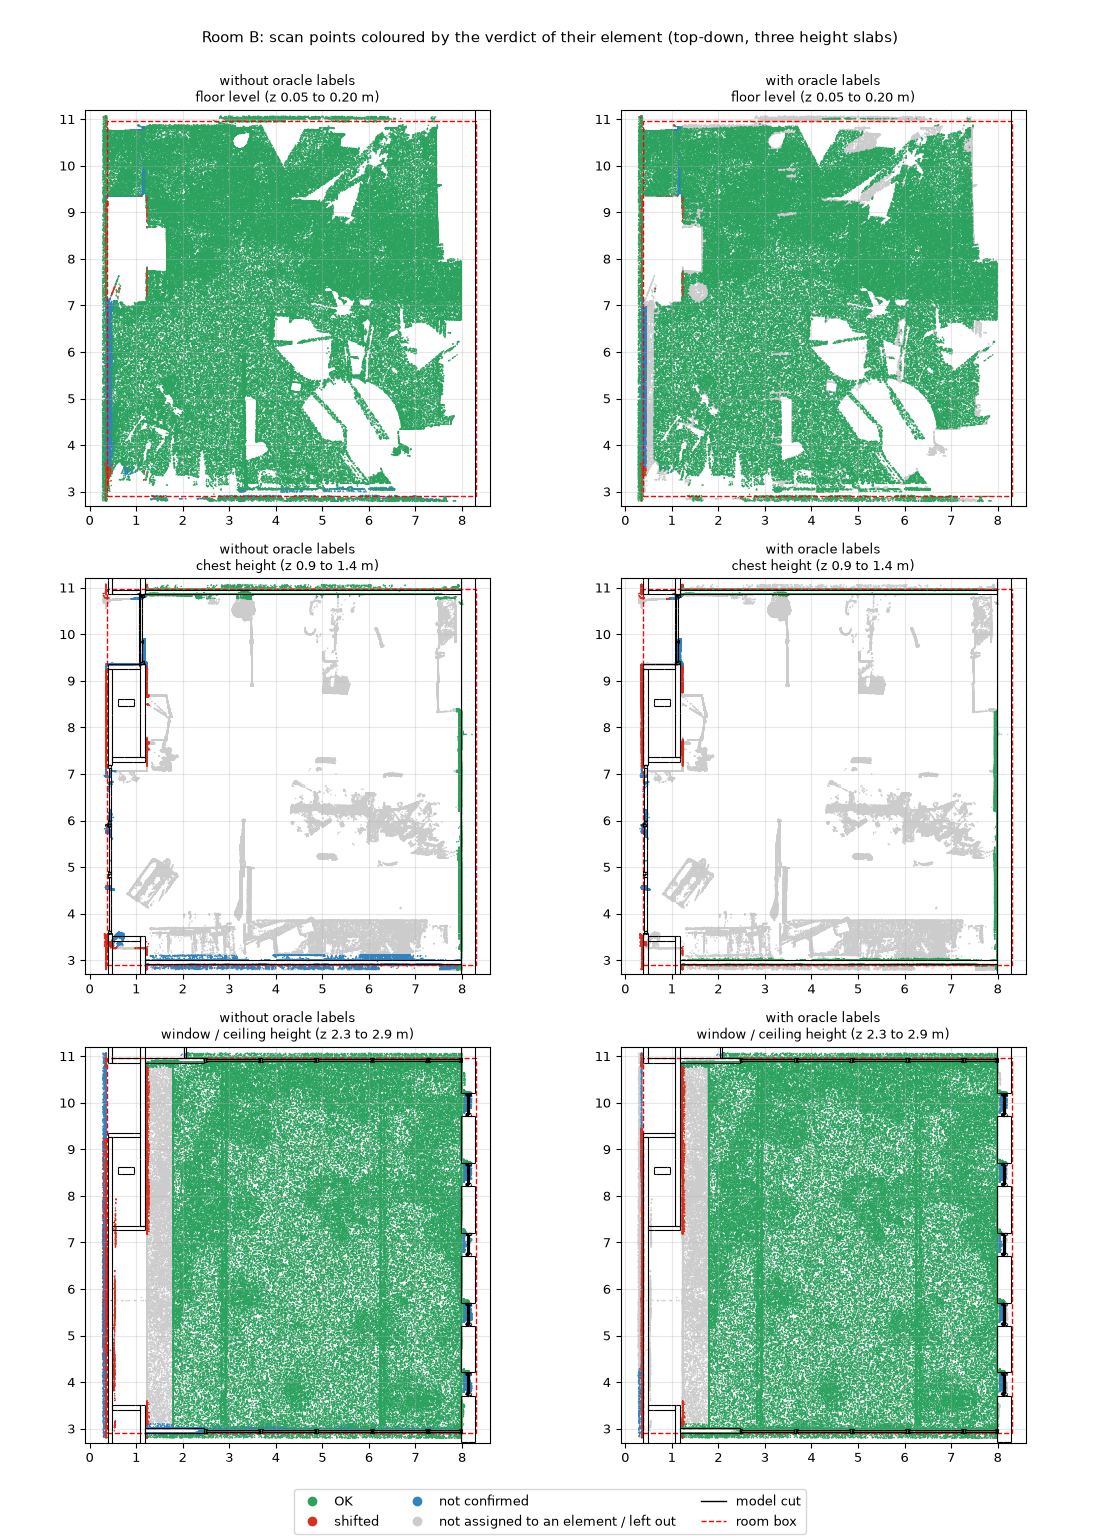

peak RSS 1.55 GB, notebook run 84 s


In [16]:
VERDICT_COLOUR = {"OK": "#2ca25f", "shifted": "#d7301f", "not confirmed": "#3182bd"}
GREY = np.array([0.80, 0.80, 0.80])
rgb = lambda h: np.array([int(h[k:k + 2], 16) / 255 for k in (1, 3, 5)])
SLABS = [("floor level (z 0.05 to 0.20 m)", 0.05, 0.20, 0.05), ("chest height (z 0.9 to 1.4 m)", 0.9, 1.4, 1.15),
         ("window / ceiling height (z 2.3 to 2.9 m)", 2.3, 2.9, 2.5)]  # name, z range, height of the model cut


def section(elements, axis, value):
    # Line segments where the plane axis == value cuts the elements' triangles: (n, 2, 2), two end points in the other two axes.
    keep = [i for i in range(3) if i != axis]
    out = []
    for e in elements:
        v = e.vertices
        if v[:, axis].min() >= value or v[:, axis].max() <= value:
            continue
        tri = v[e.faces]
        s = tri[:, :, axis] - value
        S = np.full((len(tri), 2, 2), np.nan)
        count = np.zeros(len(tri), int)
        for i, j in ((0, 1), (1, 2), (2, 0)):
            idx = np.where(s[:, i] * s[:, j] < 0)[0]
            t = s[idx, i] / (s[idx, i] - s[idx, j])
            S[idx, count[idx]] = tri[idx, i][:, keep] + t[:, None] * (tri[idx, j][:, keep] - tri[idx, i][:, keep])
            count[idx] += 1
        out.append(S[count == 2])
    return np.concatenate(out) if out else np.zeros((0, 2, 2))


rs = np.random.default_rng(SEED)
fig, axs = plt.subplots(3, 2, figsize=(11, 15.4))
for row, (title, z0, z1, z_cut) in enumerate(SLABS):
    slab = np.flatnonzero((P[:, 2] >= z0) & (P[:, 2] <= z1))
    pick = np.sort(rs.choice(slab, min(150_000, len(slab)), replace=False))
    cuts = section(elements, 2, z_cut)
    for col, (rows, use, label) in enumerate(((rows_no_labels, np.ones(len(P), bool), "without oracle labels"),
                                              (rows_oracle, is_element_class, "with oracle labels"))):
        element_colour = np.array([rgb(VERDICT_COLOUR[r["verdict"]]) for r in rows])
        coloured = in_band[pick] & use[pick]
        colour = np.where(coloured[:, None], element_colour[geom_id[pick]], GREY)
        order = np.argsort(coloured, kind="stable")  # grey first, verdict colours on top
        ax = axs[row, col]
        ax.scatter(P[pick[order], 0], P[pick[order], 1], s=1.2, c=colour[order], linewidths=0, rasterized=True)
        ax.add_collection(LineCollection(cuts, colors="k", linewidths=0.8))
        ax.add_patch(plt.Rectangle(box_lo[:2], *(box_hi - box_lo)[:2], fill=False, ec="r", ls="--", lw=1))
        ax.set_xlim(-0.1, 8.6); ax.set_ylim(2.7, 11.2); ax.set_aspect("equal"); ax.grid(alpha=0.3)
        ax.set_title(f"{label}\n{title}", fontsize=9)
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=6, color=c, label=v) for v, c in VERDICT_COLOUR.items()] +
           [plt.Line2D([], [], marker="o", ls="", ms=6, color=GREY, label="not assigned to an element / left out"),
            plt.Line2D([], [], color="k", lw=1, label="model cut"), plt.Line2D([], [], color="r", ls="--", lw=1, label="room box")],
           loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Room B: scan points coloured by the verdict of their element (top-down, three height slabs)")
plt.tight_layout(rect=(0, 0.04, 1, 0.98))
fig.savefig(OUT / "verdicts_top_down.png")
plt.close(fig)
display(Image(filename=str(OUT / "verdicts_top_down.png"), width=1000))
print(f"peak RSS {peak_rss_gb():.2f} GB, notebook run {time.time() - T0:.0f} s")


## Answer

Room B of the CRAS lab, 35 elements, USIBD LOA30 (15 mm at 2 sigma), one transform (refined from 01's, no labels) for both runs.

**Verdicts.** Without oracle labels: **16 OK, 5 shifted, 14 not confirmed**. With oracle labels: **17 OK, 7 shifted, 11 not confirmed**. Missing and not visible do not occur: 01 recovered no scanner positions (1 of 21, outside the box), so that branch is not implemented.

- **OK (16 without labels):** the ceiling covering inside the box, two more coverings and the floor slab and 2 walls that the box only partly holds (judged on the part it holds), and 10 of the 16 windows. The 10 windows have median offsets within 2 mm and 87 to 98 % of their points inside 15 mm.
- **Shifted (5 without labels, 7 with):** walls only, all with the median offset positive and between +35 and +54 mm, spread 3 to 11 mm. With labels two more walls (+38 mm, and +95 mm, the latter bimodal: 47 % of its points are inside the tolerance and the median falls in the cluster at the band edge, so read it as "something else is there" rather than "this wall is 95 mm off"). Offsets are signed along the normal of the nearest face, so for the thin west wall (+35 mm) the nearest face is its outer one and its scan surface (median x 0.356 m) lies 13 cm from the modelled room-facing face (x 0.49 m): shifts of a 10 cm wall beyond about 5 cm are measured against the far face and read too small. I did not look into why the shifted walls all have a positive offset of 3.5 to 5.4 cm (finish layers missing from the model, or a real displacement); the scan alone does not say.
- **Not confirmed (14 / 11):** without labels, 11 of the 14 are "inconsistent offsets" (the door, 5 of the 6 windows that are not OK, 4 walls, 1 covering) and 3 are "too few points": the column, which has 78 points within 10 cm (none with labels: the scan holds almost nothing there, and without scanner positions that cannot be called missing or not visible), a window with 1,965 points (35 short of `MIN_POINTS`, and its offsets are scattered anyway), and a covering that is outside the box.
- **With vs without labels:** 3 walls change (`Drywall:961571` not confirmed -> OK, `Drywall:976859` and `Drywall:977311` not confirmed -> shifted, 3,255 and 29,000 points without labels, 2,394 and 5,469 with). The only difference between the runs is the points, so the cause is clutter and unassigned points within 10 cm of these walls: they add other offsets (spread 75 mm without labels, 7.5 mm with, on the first of the two shifted walls). The other 32 verdicts agree. That 3 of 35 move is an upper bound on what segmentation is worth in this room; the choice of crop (below) moves more verdicts than the labels do.

**Frame.** The coarse check does not confirm the recorded transform and does not refute it: in the as-delivered frame, FPFH + RANSAC lands within 2 degrees and 5 cm of it on **0 of 5** seeds (rotations of 79 to 172 degrees, room centroid 0.3 to 1.2 m off), which is what a cluttered, nearly box-shaped room does to it (02 saw the same on UVigo). ICP started from the recorded transform stays where it is: the correction is **0.11 degrees and 6.8 mm** at the room centroid (sanity bounds 0.5 degrees and 5 cm), and refining on oracle-label points only differs from the no-label refinement by 0.009 degrees and 0.3 mm. Registration residual after refinement for the element-class points in the box: median 5.4 mm, p90 40 mm, p99 247 mm (floor: p99 12 mm).

**01's p99 tail.** 5.0 % of the element-class points lie more than 10 cm from every element, and they sit in four places, all on real surfaces the model lacks or puts elsewhere: ceiling-class points at z 2.55 to 2.66 m along x 1.3 to 1.8 m (10 % of the ceiling class, median 0.24 m from the nearest element); wall-class points at x about 1.23 m, y 3.8 to 7.2 m, median z 2.36 m, where the model's 10 cm wall at x 1.08 to 1.18 m has a gap (y 3.51 to 7.36 m); door-class points in a line at y 10.75 m, 11 cm from the nearest wall face, which the one modelled door (at x 1.0 to 1.2 m) does not explain; and window-class points at x about 7.97 m, z 2.5 to 2.7 m, 13 cm in front of the glazing (a blind box or reveal, probably). So the tail looks like unmodelled or differently modelled geometry, not a registration failure. 01's 0.48 m was measured on wall-class points of the whole building, so this room explains the mechanism, not that exact number.

**Triangle winding.** All 35 elements are outward-facing: walls, slab, column and coverings are closed solids (outward share 1.00), windows and doors are unions of overlapping solids (outward share 0.67 to 0.90, inward at most 0.23), so no element was flipped.

**Partly-inside elements.** 11 of the 35 cross a box face, and their verdicts cover only the part the cropped scan reaches: 4 OK, 4 shifted, 3 not confirmed. Two of the OK are coverings with 0.2 % of their surface in the box, judged on a strip of at most 10 cm: the verdict holds for the strip only, and the `reason` column says so. The strict box (no padding) would have given 16 OK, 2 shifted, 17 not confirmed; padding the crop by the 10 cm band changes 7 elements. It lets the thin west wall be judged (83 % of its band points lie outside the box, whose west face is 1 cm outside the wall: not confirmed with 25,652 points strict, shifted with 148,667 padded) and two more walls become shifted, and two coverings get a verdict; but it also turns two OK walls (`Drywall:961571`, `Drywall:977311`) into not confirmed (77 and 78 % of their points inside 15 mm, against the 80 % rule), because the padding admits points beyond the box. Verdicts of walls that lie on a box face are therefore sensitive to the crop; a box whose faces sit on wall centre lines (or per-element surface patches) would be cleaner than either.

**Judgement calls.** `MIN_POINTS` between 200 and 2,000 changes nothing; 20,000 would leave almost everything not confirmed. A 95 % share within the tolerance (the spec's confidence level) instead of 80 % gives 7 OK / 5 shifted / 23 not confirmed without labels and 9 / 7 / 19 with, so the OK count depends on that threshold more than on anything else here. The `shifted` rule, taken from 00, accepts a bimodal distribution whose majority cluster is offset.
